# Machine Predictive Maintenance Expert System

**Dataset:** [Machine Predictive Maintenance Classification Dataset](https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification)

**Goal:** Binary classification - `Target`: 0 = No failure, 1 = Failure
> The column `Failure Type` is **excluded** (data leakage)

---
## 1. Imports and Config

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import warnings
warnings.filterwarnings('ignore')

---
## 2. Data Loading

In [2]:
df = pd.read_csv('predictive_maintenance.csv')

---
## Initial Inspection

In [3]:
print("- Dataset Info -")
print(df.info())

print("\n- Missing Values -")
if(df.isnull().sum().sum() != 0):
    print(df.isnull().sum())
else:
    print("No missing values found.")

- Dataset Info -
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
None

- Missing Values -
No missing values found.


---
## 3. Descriptive statistic

In [4]:
num_features = ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

print("- Descriptive statistics of numerical features -")
df[num_features + ['Target']].describe().round(3)

- Descriptive statistics of numerical features -


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,300.005,310.006,1538.776,39.987,107.951,0.034
std,2.000,1.484,179.284,9.969,63.654,0.181
min,295.300,305.700,1168.000,3.800,0.000,0.000
25%,298.300,308.800,1423.000,33.200,53.000,0.000
50%,300.100,310.100,1503.000,40.100,108.000,0.000
75%,301.500,311.100,1612.000,46.800,162.000,0.000
max,304.500,313.800,2886.000,76.600,253.000,1.000


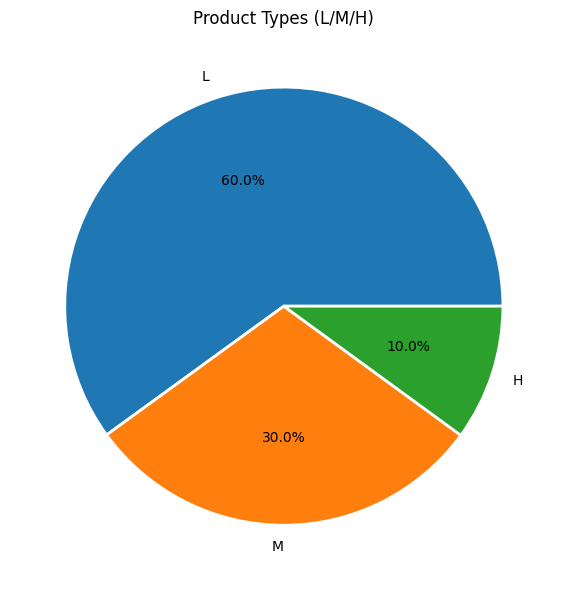

In [56]:
fig, ax = plt.subplots(figsize=(8, 6))
tc = df['Type'].value_counts()
ax.pie(tc.values, labels=tc.index, autopct='%1.1f%%', wedgeprops=dict(edgecolor='white', linewidth=2))
ax.set_title('Product Types (L/M/H)')
plt.tight_layout()
plt.show()

In [52]:
print("\n- Failures by product type -")
for t in ['H','M','L']:
    sub = df[df['Type']==t]
    rate = sub['Target'].mean()*100
    print(f"  Type {t}: {sub['Target'].sum():3d}/{len(sub):4d} ({rate:.2f}%)")


- Failures by product type -
  Type H:  21/1003 (2.09%)
  Type M:  83/2997 (2.77%)
  Type L: 235/6000 (3.92%)


---
## 4. Target Distribution

In [53]:
print("- Target variable distribution -")
vc = df['Target'].value_counts()
for k, v in vc.items():
    label = 'Failure     ' if k == 1 else 'No failure'
    print(f"  {label} (Target={k}): {v:5d} samples ({v/len(df)*100:.1f}%)")

if 0 in vc and 1 in vc:
    ratio = vc[0] / vc[1]
    print(f"\nImbalance ratio: {ratio:.1f}:1")
    if ratio > 1.2 or ratio < 0.8:
        print("Dataset is imbalanced!")
    else:
        print("Dataset is balanced.")

- Target variable distribution -
  No failure (Target=0):  9661 samples (96.6%)
  Failure      (Target=1):   339 samples (3.4%)

Imbalance ratio: 28.5:1
Dataset is imbalanced!


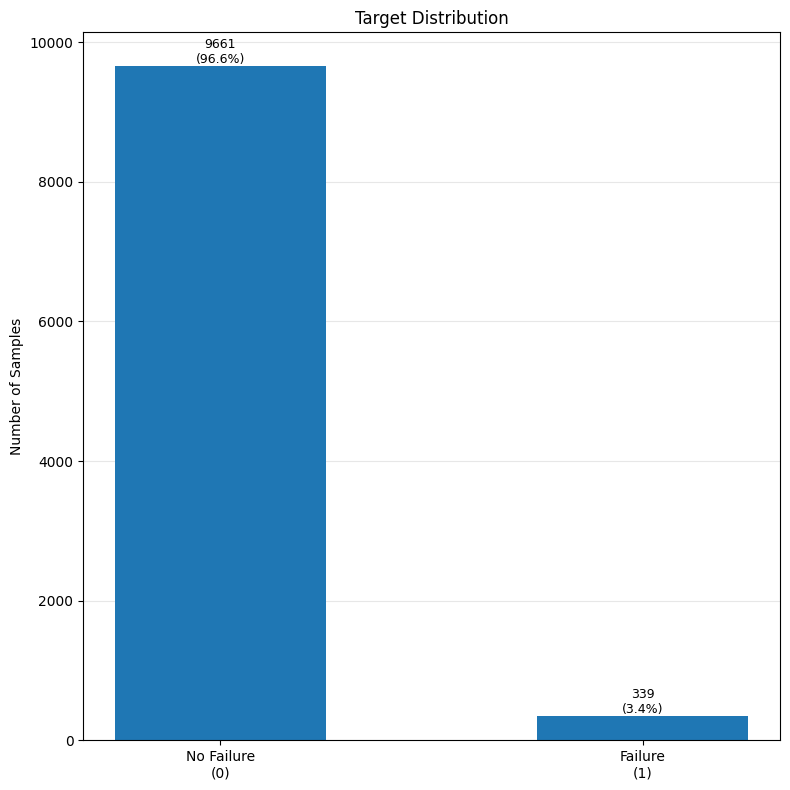

In [54]:
fig, ax = plt.subplots(figsize=(8, 8))
counts = df['Target'].value_counts().sort_index()
bars = ax.bar(['No Failure\n(0)', 'Failure\n(1)'], counts.values, width=0.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=9)
ax.set_title('Target Distribution')
ax.set_ylabel('Number of Samples')
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 5. Air Temperature Distribution

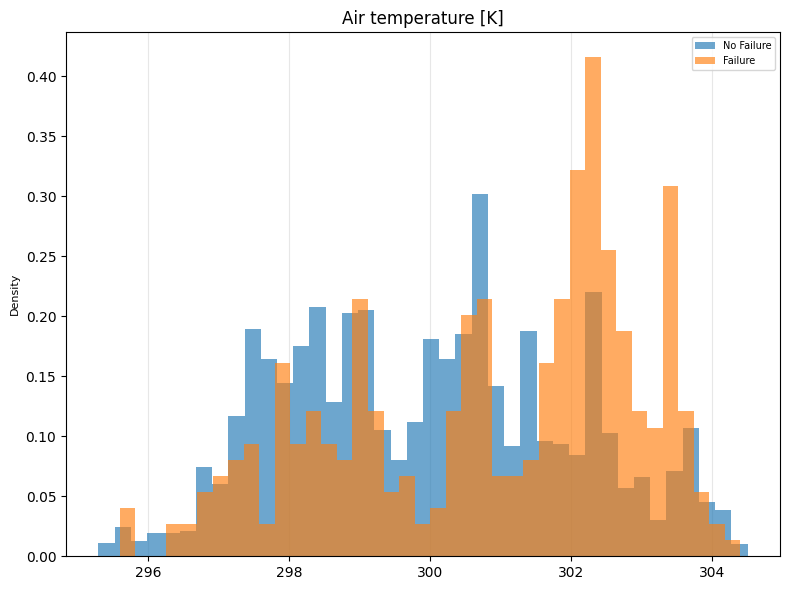

In [62]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[0]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 6. Process Temperature Distribution

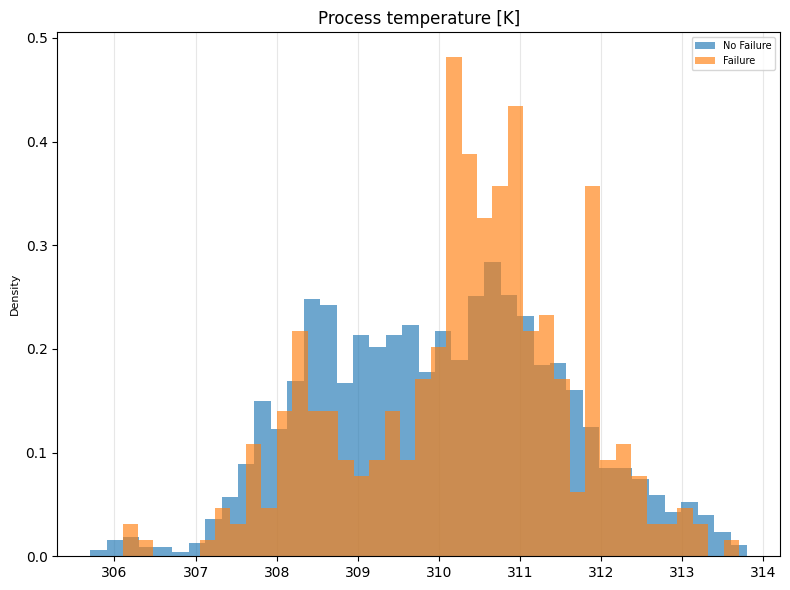

In [65]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[1]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 7. RPM Distribution

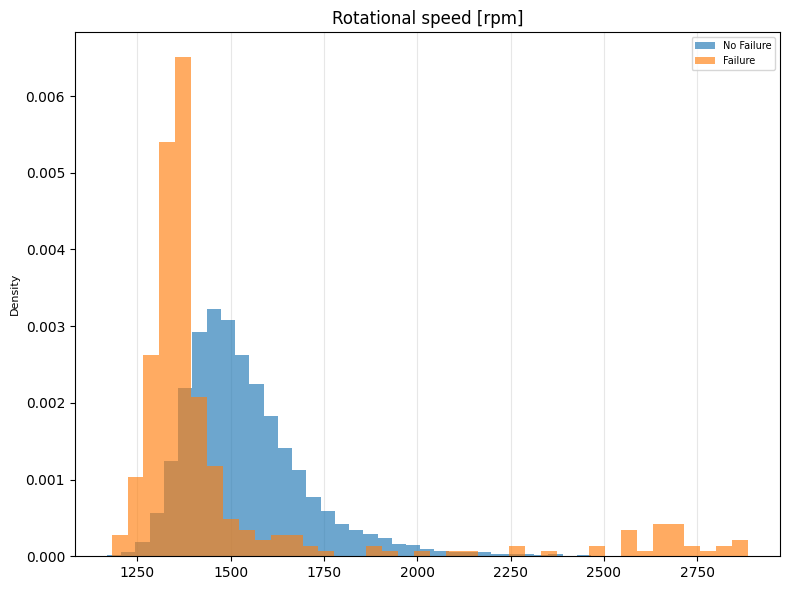

In [66]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[2]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 8. Torque Distribution

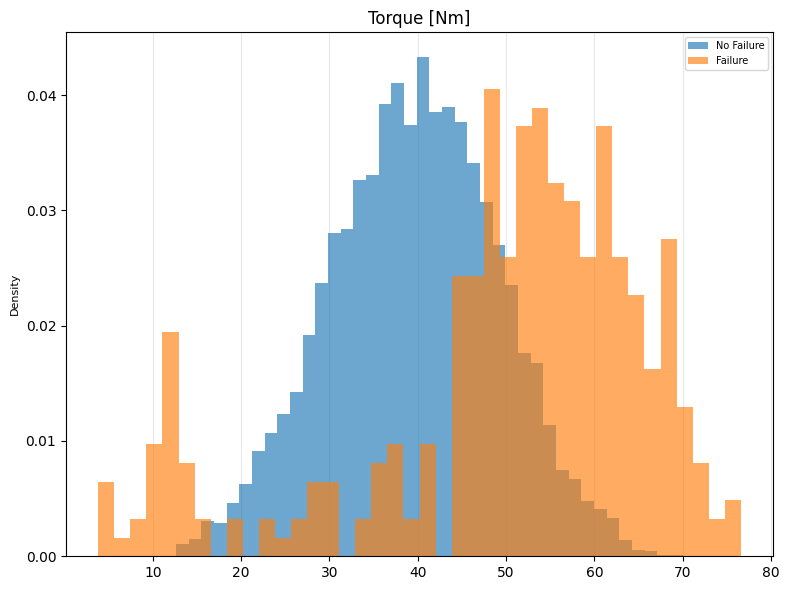

In [67]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[3]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 9. Tool Wear Distribution

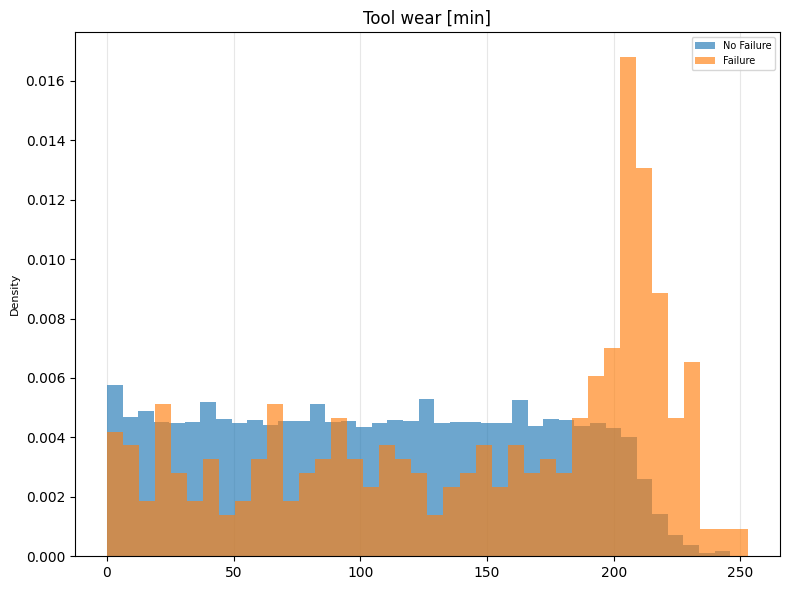

In [68]:
fig, ax = plt.subplots(figsize=(8, 6))
feat = num_features[4]
ax.hist(df[df['Target']==0][feat], bins=40, alpha=0.65, label='No Failure', density=True)
ax.hist(df[df['Target']==1][feat], bins=40, alpha=0.65, label='Failure', density=True)
ax.set_title(feat)
ax.set_ylabel('Density', fontsize=8)
ax.legend(fontsize=7)
ax.xaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

---
## 10. Correlation Matrix

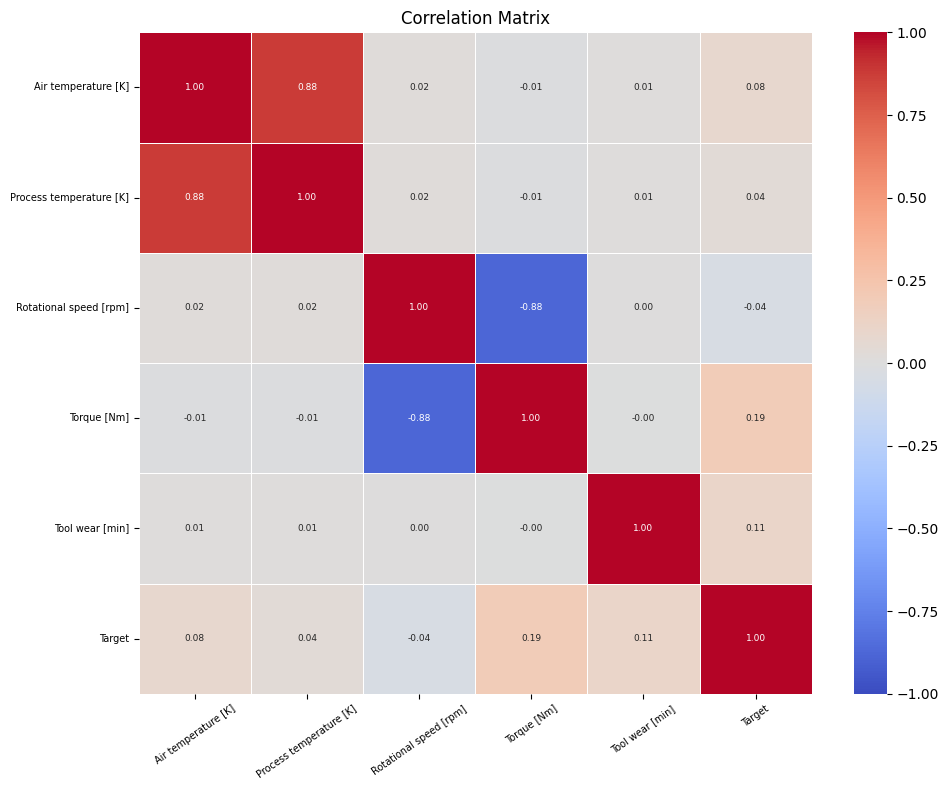

In [74]:
fig, ax = plt.subplots(figsize=(10, 8))
corr = df[num_features + ['Target']].corr()
sns.heatmap(corr, ax=ax, cmap='coolwarm', vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 6.5},
            xticklabels=num_features + ['Target'],
            yticklabels=num_features + ['Target'],
            linewidths=0.5, linecolor='white')
ax.set_title('Correlation Matrix')
ax.tick_params(axis='x', rotation=35, labelsize=7)
ax.tick_params(axis='y', rotation=0, labelsize=7)
plt.tight_layout()
plt.show()